In [1]:
import torch
from torch import nn
import sys
from matplotlib import pyplot as plt
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import dl_utils


In [3]:
net = nn.Sequential(nn.Flatten(),
                    nn.Linear(784, 256),
                    nn.ReLU(),
                    nn.Linear(256, 10))

def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=10, bias=True)
)

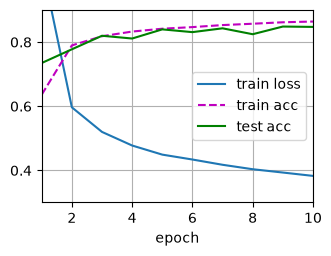

In [4]:
batch_size, lr, num_epochs = 256, 0.1, 10
loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=lr)

train_iter, test_iter = dl_utils.load_data_fashion_mnist(batch_size)
dl_utils.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

In [5]:
dl_utils.evaluate_accuracy(net, test_iter)

0.8473